In [ ]:
!pip install gdown
import gdown
import pandas as pd
# @title
P1_PATH = gdown.download("https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83", "Phase_1.xlsx", quiet=False)
P2_PATH = gdown.download("https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds", "Phase_2.xlsx", quiet=False)
P3_PATH = gdown.download("https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy", "Phase_3.xlsx", quiet=False)
df1 = pd.read_excel(P1_PATH)
df2 = pd.read_excel(P2_PATH)
df3 = pd.read_excel(P3_PATH)

Downloading...
From: https://drive.google.com/uc?id=1J97S0GDy9bJVGO6Hi0c31q-BmpCGEn83
To: /content/Phase_1.xlsx
100%|██████████| 115k/115k [00:00<00:00, 42.6MB/s]
Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 599kB/s]
Downloading...
From: https://drive.google.com/uc?id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy
To: /content/Phase_3.xlsx
100%|██████████| 367k/367k [00:00<00:00, 37.5MB/s]


Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 820kB/s]



OVERALL ISSUE SALIENCE
------------------------------------------------------------
Before: 30.3%
After:  36.2%
Change: +5.9 pp
McNemar p = 3.88476e-05

BEFORE-AFTER CHANGE × AUDIO CONDITION
------------------------------------------------------------
p = 0.6232

SYNTHETIC CLIPS ONLY
------------------------------------------------------------
N = 403
Judged fake: n = 208
Judged authentic: n = 195

BEFORE-AFTER CHANGE × AUTHENTICITY JUDGMENT
------------------------------------------------------------
Synthetic clips only
Interaction p = 0.5766

ISSUE SALIENCE BY EXPERIMENTAL CONDITION
------------------------------------------------------------
Authentic: 35.5% → 41.0% (+5.5 pp), p = 0.03469
Synthetic + authentic content: 26.9% → 34.3% (+7.5 pp), p = 0.002599
Synthetic + fabricated content: 28.7% → 33.3% (+4.6 pp), p = 0.1078

ISSUE SALIENCE BY AUTHENTICITY JUDGMENT
------------------------------------------------------------
Judged fake: 26.4% → 31.4% (+5.0 pp), p = 0.04139
Judged a

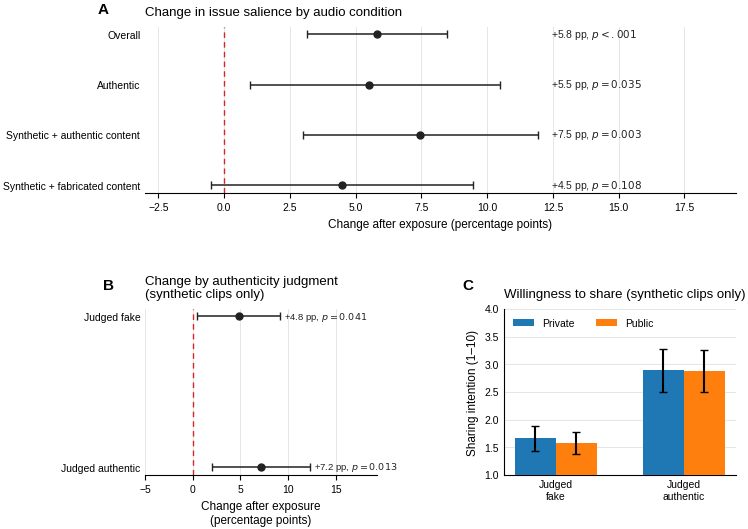

In [ ]:
# @title
# ============================================================
# STUDY 2
# ISSUE SALIENCE + AUTHENTICITY JUDGMENT + SHARING
# THREE-PANEL PUBLICATION FIGURE
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
import gdown
import re


# ============================================================
# PUBLICATION STYLE
# ============================================================

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": [
        "Arial",
        "Helvetica",
        "Liberation Sans",
        "DejaVu Sans"
    ],

    "font.size": 8.5,
    "axes.titlesize": 9.5,
    "axes.labelsize": 8.5,
    "xtick.labelsize": 7.5,
    "ytick.labelsize": 7.5,
    "legend.fontsize": 7.5,

    "axes.linewidth": 0.8,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03
})


BLUE = "#1f77b4"
ORANGE = "#ff7f0e"
BLACK = "#222222"
LIGHT_GREY = "#E8E8E8"
GRID = "#E6E6E6"
RED = "#D62728"

# ============================================================
# LOAD STUDY 2
# ============================================================

P2_PATH = gdown.download(
    "https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds",
    "Phase_2.xlsx",
    quiet=False
)

df2 = pd.read_excel(P2_PATH)

df2 = df2.reset_index(drop=True)

df2["participant_id"] = np.arange(
    len(df2)
)


# ============================================================
# CREATE ISSUE-SALIENCE VARIABLES
# ============================================================

def normalize_topic(x):

    if pd.isna(x):
        return ""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(x).lower()
    )


def contains_clip_topic(
    mip_response,
    clip_topic
):

    if (
        pd.isna(mip_response)
        or pd.isna(clip_topic)
    ):
        return np.nan

    clip = normalize_topic(
        clip_topic
    )

    selected_topics = [
        normalize_topic(x)
        for x in str(
            mip_response
        ).split(",")
    ]

    return int(
        clip in selected_topics
    )


df2["mip_before"] = df2.apply(
    lambda r: contains_clip_topic(
        r["mip_topics_before"],
        r["topic"]
    ),
    axis=1
)

df2["mip_after"] = df2.apply(
    lambda r: contains_clip_topic(
        r["mip_topics"],
        r["topic"]
    ),
    axis=1
)


# ============================================================
# LABELS
# ============================================================

group_labels = {
    1: "Authentic",
    2: "Synthetic + authentic content",
    3: "Synthetic + fabricated content"
}

group_plot_labels = {
    1: "Authentic",
    2: "Synthetic + authentic content",
    3: "Synthetic + fabricated content"
}


judgment_labels = {
    0: "Judged fake",
    1: "Judged authentic"
}


# ============================================================
# HELPERS
# ============================================================

def mean_ci(series):

    x = pd.to_numeric(
        series,
        errors="coerce"
    ).dropna()

    mean = x.mean()

    ci = (
        1.96
        * x.sem()
    )

    return mean, ci


# ------------------------------------------------------------
# Exact McNemar test
# ------------------------------------------------------------

def mcnemar_exact(
    before,
    after
):

    valid = (
        before.notna()
        & after.notna()
    )

    b = before[
        valid
    ].astype(int)

    a = after[
        valid
    ].astype(int)

    yes_to_no = (
        (b == 1)
        & (a == 0)
    ).sum()

    no_to_yes = (
        (b == 0)
        & (a == 1)
    ).sum()

    discordant = (
        yes_to_no
        + no_to_yes
    )

    if discordant == 0:
        return np.nan

    return stats.binomtest(
        no_to_yes,
        discordant,
        p=0.5,
        alternative="two-sided"
    ).pvalue


# ------------------------------------------------------------
# Paired percentage-point change + bootstrap CI
# ------------------------------------------------------------

def paired_change_ci(
    before,
    after,
    n_boot=10000,
    seed=12345
):

    valid = (
        before.notna()
        & after.notna()
    )

    b = before[
        valid
    ].astype(float).to_numpy()

    a = after[
        valid
    ].astype(float).to_numpy()

    change = (
        a - b
    ) * 100

    estimate = (
        change.mean()
    )

    rng = np.random.RandomState(
        seed
    )

    n = len(change)

    boot_estimates = np.empty(
        n_boot
    )

    for i in range(
        n_boot
    ):

        sample_idx = rng.randint(
            0,
            n,
            size=n
        )

        boot_estimates[i] = (
            change[
                sample_idx
            ].mean()
        )

    ci_low, ci_high = np.percentile(
        boot_estimates,
        [2.5, 97.5]
    )

    return (
        estimate,
        ci_low,
        ci_high
    )


def format_p(p):

    if pd.isna(p):
        return "NA"

    if p < .001:
        return r"$p<.001$"

    return rf"$p={p:.3f}$"


# ============================================================
# BASIC DESCRIPTIVES
# ============================================================

overall_before = (
    df2["mip_before"].mean()
)

overall_after = (
    df2["mip_after"].mean()
)

overall_change = (
    overall_after
    - overall_before
) * 100

overall_p = mcnemar_exact(
    df2["mip_before"],
    df2["mip_after"]
)


print(
    "\nOVERALL ISSUE SALIENCE"
)

print(
    "-" * 60
)

print(
    f"Before: "
    f"{overall_before*100:.1f}%"
)

print(
    f"After:  "
    f"{overall_after*100:.1f}%"
)

print(
    f"Change: "
    f"{overall_change:+.1f} pp"
)

print(
    f"McNemar p = "
    f"{overall_p:.6g}"
)


# ============================================================
# PANEL A STATISTICS
# BEFORE-AFTER × EXPERIMENTAL CONDITION
# ============================================================

before_long = df2[
    [
        "participant_id",
        "group_no",
        "mip_before"
    ]
].copy()

before_long = before_long.rename(
    columns={
        "mip_before": "salience"
    }
)

before_long["post"] = 0


after_long = df2[
    [
        "participant_id",
        "group_no",
        "mip_after"
    ]
].copy()

after_long = after_long.rename(
    columns={
        "mip_after": "salience"
    }
)

after_long["post"] = 1


salience_long = pd.concat(
    [
        before_long,
        after_long
    ],
    ignore_index=True
)

salience_long = salience_long.dropna(
    subset=[
        "salience",
        "group_no",
        "participant_id"
    ]
)


condition_gee = smf.gee(
    formula=(
        "salience ~ "
        "post * "
        "C(group_no, Treatment(reference=1))"
    ),
    groups="participant_id",
    data=salience_long,
    family=sm.families.Binomial(),
    cov_struct=(
        sm.cov_struct.Exchangeable()
    )
).fit()


condition_interactions = [
    name
    for name
    in condition_gee.params.index
    if name.startswith(
        "post:C(group_no"
    )
]


R_condition = np.zeros(
    (
        len(condition_interactions),
        len(condition_gee.params)
    )
)


for row_i, name in enumerate(
    condition_interactions
):

    col_i = list(
        condition_gee.params.index
    ).index(name)

    R_condition[
        row_i,
        col_i
    ] = 1


condition_test = (
    condition_gee.wald_test(
        R_condition,
        scalar=True
    )
)

condition_interaction_p = float(
    condition_test.pvalue
)


print(
    "\nBEFORE-AFTER CHANGE × AUDIO CONDITION"
)

print(
    "-" * 60
)

print(
    f"p = "
    f"{condition_interaction_p:.4f}"
)


# ============================================================
# SYNTHETIC CLIPS ONLY
# Used for Panels B and C
# ============================================================

synthetic = df2[
    df2[
        "group_no"
    ].isin(
        [2, 3]
    )
].copy()


# Keep clear binary authenticity judgments
synthetic = synthetic[
    synthetic[
        "realness_perception"
    ].isin(
        [0, 1]
    )
].copy()


print(
    "\nSYNTHETIC CLIPS ONLY"
)

print(
    "-" * 60
)

print(
    f"N = {len(synthetic)}"
)

for judgment in [
    0,
    1
]:

    n = (
        synthetic[
            "realness_perception"
        ]
        .eq(judgment)
        .sum()
    )

    print(
        f"{judgment_labels[judgment]}: "
        f"n = {n}"
    )


# ============================================================
# PANEL B STATISTICS
# BEFORE-AFTER × AUTHENTICITY JUDGMENT
# SYNTHETIC CLIPS ONLY
# ============================================================

auth_before = synthetic[
    [
        "participant_id",
        "realness_perception",
        "mip_before"
    ]
].copy()

auth_before = auth_before.rename(
    columns={
        "mip_before": "salience"
    }
)

auth_before["post"] = 0


auth_after = synthetic[
    [
        "participant_id",
        "realness_perception",
        "mip_after"
    ]
].copy()

auth_after = auth_after.rename(
    columns={
        "mip_after": "salience"
    }
)

auth_after["post"] = 1


auth_long = pd.concat(
    [
        auth_before,
        auth_after
    ],
    ignore_index=True
)


auth_long = auth_long.dropna(
    subset=[
        "participant_id",
        "realness_perception",
        "salience"
    ]
)


auth_gee = smf.gee(
    formula=(
        "salience ~ "
        "post * "
        "C(realness_perception, "
        "Treatment(reference=0))"
    ),
    groups="participant_id",
    data=auth_long,
    family=sm.families.Binomial(),
    cov_struct=(
        sm.cov_struct.Exchangeable()
    )
).fit()


auth_interactions = [
    name
    for name
    in auth_gee.params.index
    if name.startswith(
        "post:C(realness_perception"
    )
]


R_auth = np.zeros(
    (
        len(auth_interactions),
        len(auth_gee.params)
    )
)


for row_i, name in enumerate(
    auth_interactions
):

    col_i = list(
        auth_gee.params.index
    ).index(name)

    R_auth[
        row_i,
        col_i
    ] = 1


auth_test = auth_gee.wald_test(
    R_auth,
    scalar=True
)

auth_interaction_p = float(
    auth_test.pvalue
)


print(
    "\nBEFORE-AFTER CHANGE × AUTHENTICITY JUDGMENT"
)

print(
    "-" * 60
)

print(
    "Synthetic clips only"
)

print(
    f"Interaction p = "
    f"{auth_interaction_p:.4f}"
)


# ============================================================
# PRINT CONDITION-SPECIFIC CHANGES
# ============================================================

print(
    "\nISSUE SALIENCE BY EXPERIMENTAL CONDITION"
)

print(
    "-" * 60
)

for g in [
    1,
    2,
    3
]:

    sub = df2[
        df2[
            "group_no"
        ].eq(g)
    ]

    before = (
        sub[
            "mip_before"
        ].mean()
    )

    after = (
        sub[
            "mip_after"
        ].mean()
    )

    p = mcnemar_exact(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ]
    )

    print(
        f"{group_labels[g]}: "
        f"{before*100:.1f}% → "
        f"{after*100:.1f}% "
        f"({(after-before)*100:+.1f} pp), "
        f"p = {p:.4g}"
    )


# ============================================================
# PRINT AUTHENTICITY-JUDGMENT CHANGES
# ============================================================

print(
    "\nISSUE SALIENCE BY AUTHENTICITY JUDGMENT"
)

print(
    "-" * 60
)

for judgment in [
    0,
    1
]:

    sub = synthetic[
        synthetic[
            "realness_perception"
        ].eq(judgment)
    ]

    before = (
        sub[
            "mip_before"
        ].mean()
    )

    after = (
        sub[
            "mip_after"
        ].mean()
    )

    p = mcnemar_exact(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ]
    )

    print(
        f"{judgment_labels[judgment]}: "
        f"{before*100:.1f}% → "
        f"{after*100:.1f}% "
        f"({(after-before)*100:+.1f} pp), "
        f"p = {p:.4g}"
    )


# ============================================================
# SHARING DESCRIPTIVES
# SYNTHETIC CLIPS ONLY
# ============================================================

print(
    "\nSHARING BY AUTHENTICITY JUDGMENT"
)

print(
    "-" * 60
)

for judgment in [
    0,
    1
]:

    sub = synthetic[
        synthetic[
            "realness_perception"
        ].eq(judgment)
    ]

    print(
        f"{judgment_labels[judgment]}: "
        f"private = "
        f"{sub['share_likely_private'].mean():.2f}, "
        f"public = "
        f"{sub['share_likely_public'].mean():.2f}"
    )


# ============================================================
# CREATE FIGURE
#
# A spans the full top row.
# B and C share the bottom row.
# This is much more readable than a 1 × 3 layout.
# ============================================================

fig = plt.figure(
    figsize=(7.2, 5.4)
)

gs = fig.add_gridspec(
    2,
    2,
    height_ratios=[
        1.0,
        1.0
    ],
    hspace=0.70,
    wspace=0.55
)

axA = fig.add_subplot(
    gs[0, :]
)

axB = fig.add_subplot(
    gs[1, 0]
)

axC = fig.add_subplot(
    gs[1, 1]
)


# ============================================================
# PANEL A
# CHANGE IN ISSUE SALIENCE BY EXPERIMENTAL CONDITION
# ============================================================

plot_rows_A = []


# Overall
est, lo, hi = paired_change_ci(
    df2["mip_before"],
    df2["mip_after"],
    seed=12345
)

plot_rows_A.append({
    "label": "Overall",
    "estimate": est,
    "low": lo,
    "high": hi,
    "p": overall_p
})


# Individual experimental conditions
for g in [
    1,
    2,
    3
]:

    sub = df2[
        df2[
            "group_no"
        ].eq(g)
    ]

    est, lo, hi = paired_change_ci(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ],
        seed=12345 + g
    )

    p = mcnemar_exact(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ]
    )

    plot_rows_A.append({
        "label": group_plot_labels[g],
        "estimate": est,
        "low": lo,
        "high": hi,
        "p": p
    })


labels_A = [
    r["label"]
    for r in plot_rows_A
]

estimates_A = np.array([
    r["estimate"]
    for r in plot_rows_A
])

low_A = np.array([
    r["low"]
    for r in plot_rows_A
])

high_A = np.array([
    r["high"]
    for r in plot_rows_A
])

p_A = [
    r["p"]
    for r in plot_rows_A
]


y_A = np.arange(
    len(plot_rows_A)
)[::-1]


xerr_A = np.vstack([
    estimates_A - low_A,
    high_A - estimates_A
])


# Black estimates and confidence intervals
axA.errorbar(
    estimates_A,
    y_A,
    xerr=xerr_A,
    fmt="o",
    color=BLACK,
    ecolor=BLACK,
    markerfacecolor=BLACK,
    markeredgecolor=BLACK,
    markersize=5.0,
    elinewidth=1.1,
    capsize=3,
    capthick=1.0,
    zorder=3
)


# Red zero-reference line
axA.axvline(
    0,
    color=RED,
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=1
)


# Numeric annotations
annotation_x_A = (
    high_A.max()
    + 0.5
)


for (
    yi,
    estimate,
    p
) in zip(
    y_A,
    estimates_A,
    p_A
):

    axA.text(
        annotation_x_A,
        yi,
        (
            f"{estimate:+.1f} pp, "
            f"{format_p(p)}"
        ),
        va="center",
        ha="left",
        fontsize=7.5,
        color=BLACK
    )


axA.set_yticks(
    y_A
)

axA.set_yticklabels(
    labels_A
)

axA.set_xlabel(
    "Change after exposure (percentage points)"
)

axA.set_title(
    "Change in issue salience by audio condition",
    loc="left",
    pad=8
)


axA.grid(
    axis="x",
    color=GRID,
    linewidth=0.7
)

axA.set_axisbelow(
    True
)


# Enough room for annotations
axA.set_xlim(
    min(
        -3,
        low_A.min() - 1
    ),
    annotation_x_A + 7
)


axA.tick_params(
    axis="y",
    length=0
)

axA.spines[
    "top"
].set_visible(False)

axA.spines[
    "right"
].set_visible(False)

axA.spines[
    "left"
].set_visible(False)


axA.text(
    -0.08,
    1.08,
    "A",
    transform=axA.transAxes,
    fontsize=11,
    fontweight="bold",
    color="black"
)


# ============================================================
# PANEL B
# CHANGE IN ISSUE SALIENCE BY AUTHENTICITY JUDGMENT
# SYNTHETIC CLIPS ONLY
# ============================================================

plot_rows_B = []


for judgment in [
    0,
    1
]:

    sub = synthetic[
        synthetic[
            "realness_perception"
        ].eq(judgment)
    ]

    est, lo, hi = paired_change_ci(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ],
        seed=20000 + judgment
    )

    p = mcnemar_exact(
        sub[
            "mip_before"
        ],
        sub[
            "mip_after"
        ]
    )

    plot_rows_B.append({
        "label": judgment_labels[
            judgment
        ],
        "estimate": est,
        "low": lo,
        "high": hi,
        "p": p
    })


labels_B = [
    r["label"]
    for r in plot_rows_B
]

estimates_B = np.array([
    r["estimate"]
    for r in plot_rows_B
])

low_B = np.array([
    r["low"]
    for r in plot_rows_B
])

high_B = np.array([
    r["high"]
    for r in plot_rows_B
])

p_B = [
    r["p"]
    for r in plot_rows_B
]


y_B = np.arange(
    len(plot_rows_B)
)[::-1]


xerr_B = np.vstack([
    estimates_B - low_B,
    high_B - estimates_B
])


axB.errorbar(
    estimates_B,
    y_B,
    xerr=xerr_B,
    fmt="o",
    color=BLACK,
    ecolor=BLACK,
    markerfacecolor=BLACK,
    markeredgecolor=BLACK,
    markersize=5.0,
    elinewidth=1.1,
    capsize=3,
    capthick=1.0,
    zorder=3
)


axB.axvline(
    0,
    color=RED,
    linestyle=(0, (4, 3)),
    linewidth=1.0,
    zorder=1
)


for yi, estimate, hi, p in zip(
    y_B,
    estimates_B,
    high_B,
    p_B
):
    axB.text(
        hi + 0.45,
        yi,
        f"{estimate:+.1f} pp, {format_p(p)}",
        va="center",
        ha="left",
        fontsize=6.8,
        color=BLACK
    )


axB.set_yticks(
    y_B
)

axB.set_yticklabels(
    labels_B
)

axB.set_xlabel(
    "Change after exposure\n(percentage points)"
)

axB.set_title(
    "Change by authenticity judgment\n(synthetic clips only)",
    loc="left",
    pad=8
)


axB.grid(
    axis="x",
    color=GRID,
    linewidth=0.7
)

axB.set_axisbelow(
    True
)


axB.set_xlim(
    min(
        -5,
        low_B.min() - 1
    ),
    max(
        15,
        high_B.max() + 7
    )
)


axB.tick_params(
    axis="y",
    length=0
)

axB.spines[
    "top"
].set_visible(False)

axB.spines[
    "right"
].set_visible(False)

axB.spines[
    "left"
].set_visible(False)


axB.text(
    -0.18,
    1.12,
    "B",
    transform=axB.transAxes,
    fontsize=11,
    fontweight="bold",
    color="black"
)


# ============================================================
# PANEL C
# SHARING BY AUTHENTICITY JUDGMENT
# SYNTHETIC CLIPS ONLY
# ============================================================

# ============================================================
# PANEL C
# SHARING BY AUTHENTICITY JUDGMENT
# SYNTHETIC CLIPS ONLY
# ============================================================

x_share = np.arange(2)
width = 0.32

sharing_vars = [
    ("share_likely_private", "Private", BLUE),
    ("share_likely_public", "Public", ORANGE)
]

all_upper = []

for i, (var, label, color) in enumerate(sharing_vars):

    means = []
    cis = []

    for judgment in [0, 1]:

        values = synthetic.loc[
            synthetic["realness_perception"].eq(judgment),
            var
        ]

        mean, ci = mean_ci(values)

        means.append(mean)
        cis.append(ci)
        all_upper.append(mean + ci)

    offset = (i - 0.5) * width

    axC.bar(
        x_share + offset,
        means,
        width=width,
        yerr=cis,
        capsize=3,
        color=color,
        edgecolor="none",
        linewidth=0.8,
        label=label,
        zorder=3
    )

axC.set_xticks(x_share)
axC.set_xticklabels([
    "Judged\nfake",
    "Judged\nauthentic"
])

axC.set_ylabel("Sharing intention (1–10)")
axC.set_title(
    "Willingness to share (synthetic clips only)",
    loc="left",
    pad=8
)

axC.set_ylim(1, max(4.0, max(all_upper) + 0.4))

axC.grid(axis="y", color=GRID, linewidth=0.7)
axC.set_axisbelow(True)

axC.legend(
    frameon=False,
    ncol=2,
    loc="upper left",
    bbox_to_anchor=(0.0, 1.00)
)

axC.tick_params(axis="both", length=0)

axC.spines["top"].set_visible(False)
axC.spines["right"].set_visible(False)

axC.text(
    -0.18,
    1.12,
    "C",
    transform=axC.transAxes,
    fontsize=11,
    fontweight="bold",
    color="black"
)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(
    left=0.16,
    right=0.98,
    bottom=0.11,
    top=0.94
)


# ============================================================
# SAVE
# ============================================================

plt.savefig(
    "Figure_2_salience_authenticity_sharing.pdf",
    bbox_inches="tight",
    pad_inches=0.03
)

plt.savefig(
    "Figure_2_salience_authenticity_sharing.png",
    dpi=600,
    bbox_inches="tight",
    pad_inches=0.03,
    facecolor="white"
)

plt.show()

Downloading...
From (original): https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds
From (redirected): https://docs.google.com/spreadsheets/d/1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds/export?format=xlsx
To: /content/Phase_2.xlsx
212kB [00:00, 816kB/s]


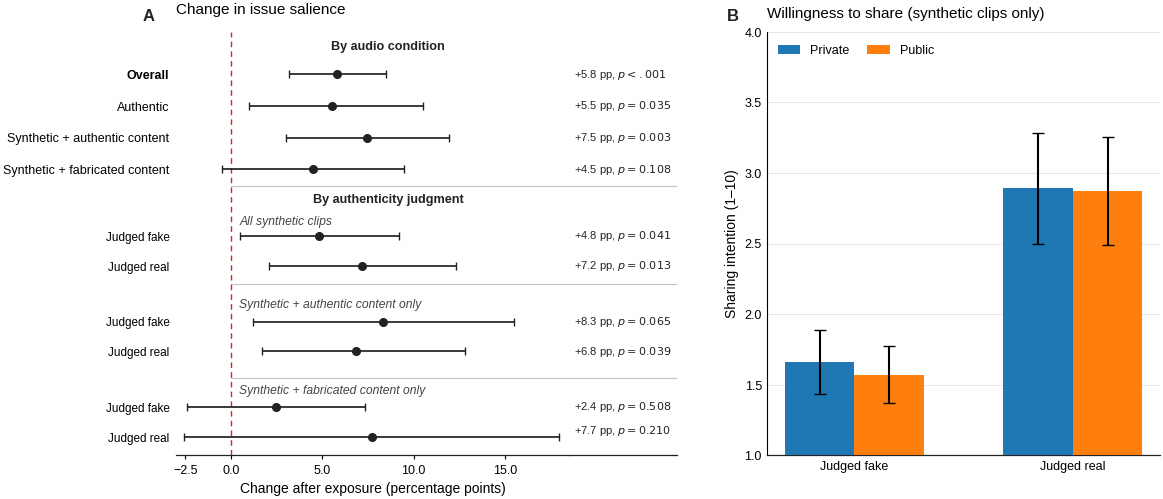


FIGURE 2 RESULTS

Overall issue salience: 30.3% -> 36.2% (+5.9 pp), p = 3.88476e-05

Before-after change x audio condition: p = 0.6232

Before-after change x authenticity judgment (ALL synthetic clips): p = 0.5766
Before-after change x authenticity judgment (synthetic + authentic content only): p = 0.6595
Before-after change x authenticity judgment (synthetic + fabricated content only): p = 0.3776

BY AUDIO CONDITION
--------------------------------------------------------------------------------
Authentic: 35.5% -> 41.0% (+5.5 pp), p = 0.03469, n = 200
Synthetic + authentic content: 26.9% -> 34.3% (+7.5 pp), p = 0.002599, n = 201
Synthetic + fabricated content: 28.7% -> 33.3% (+4.6 pp), p = 0.1078, n = 202

BY AUTHENTICITY JUDGMENT — ALL SYNTHETIC CLIPS
--------------------------------------------------------------------------------
Judged fake: 26.4% -> 31.4% (+5.0 pp), p = 0.04139, n = 208
Judged real: 29.2% -> 36.4% (+7.2 pp), p = 0.01254, n = 195

BY AUTHENTICITY JUDGMENT — SYNTH

In [ ]:
# @title
# ============================================================
# STUDY 2
# ISSUE SALIENCE + AUTHENTICITY JUDGMENT + SHARING
#
# PANEL A:
#   Change in issue salience
#   - Overall
#   - By audio condition
#   - By authenticity judgment:
#       * All synthetic clips
#       * Synthetic + authentic content only
#       * Synthetic + fabricated content only
#
# PANEL B:
#   Sharing intention by authenticity judgment
#
# LAYOUT:
#   Panel A ≈ 56%
#   Panel B ≈ 44%
#
# Panel A contains:
#   Forest plot + integrated statistics column
# ============================================================


# ============================================================
# IMPORTS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

from scipy import stats

import statsmodels.api as sm
import statsmodels.formula.api as smf

import gdown
import re


# ============================================================
# PUBLICATION STYLE
# ============================================================

mpl.rcParams.update({

    "font.family": "sans-serif",

    "font.sans-serif": [
        "Arial",
        "Helvetica",
        "Liberation Sans",
        "DejaVu Sans"
    ],

    "font.size": 9.5,

    "axes.titlesize": 11,
    "axes.labelsize": 10,

    "xtick.labelsize": 9,
    "ytick.labelsize": 9,

    "legend.fontsize": 9,

    "axes.linewidth": 0.8,

    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,

    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",

    "figure.facecolor": "white",
    "axes.facecolor": "white",

    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.03
})


# ============================================================
# COLOURS
# ============================================================

BLUE = "#1f77b4"
ORANGE = "#ff7f0e"

BLACK = "#222222"

SUBHEAD_GREY = "#444444"

LIGHT_GREY = "#C5C5C5"
GRID = "#E6E6E6"

RED = "#D62728"


# ============================================================
# LOAD STUDY 2
# ============================================================

P2_PATH = gdown.download(

    "https://drive.google.com/uc?id=1JypKPmsKEp_mcumARoE8wF5q7RhKV0EuBTmoTx51Zds",

    "Phase_2.xlsx",

    quiet=False
)


df2 = pd.read_excel(
    P2_PATH
)


df2 = df2.reset_index(
    drop=True
)


df2["participant_id"] = np.arange(
    len(df2)
)


# ============================================================
# CREATE ISSUE-SALIENCE VARIABLES
# ============================================================

def normalize_topic(x):

    if pd.isna(x):
        return ""

    return re.sub(
        r"[^a-z0-9]",
        "",
        str(x).lower()
    )


def contains_clip_topic(
    mip_response,
    clip_topic
):

    if (
        pd.isna(mip_response)
        or
        pd.isna(clip_topic)
    ):
        return np.nan


    clip = normalize_topic(
        clip_topic
    )


    selected_topics = [

        normalize_topic(x)

        for x in str(
            mip_response
        ).split(",")

    ]


    return int(
        clip in selected_topics
    )


df2["mip_before"] = df2.apply(

    lambda r: contains_clip_topic(

        r["mip_topics_before"],

        r["topic"]

    ),

    axis=1
)


df2["mip_after"] = df2.apply(

    lambda r: contains_clip_topic(

        r["mip_topics"],

        r["topic"]

    ),

    axis=1
)


# ============================================================
# LABELS
# ============================================================

group_labels = {

    1: "Authentic",

    2: "Synthetic + authentic content",

    3: "Synthetic + fabricated content"

}


judgment_labels = {

    0: "Judged fake",

    1: "Judged real"

}


# ============================================================
# HELPERS
# ============================================================

def mean_ci(series):

    x = pd.to_numeric(
        series,
        errors="coerce"
    ).dropna()


    mean = x.mean()


    ci = (
        1.96
        *
        x.sem()
    )


    return mean, ci


# ------------------------------------------------------------
# Exact McNemar
# ------------------------------------------------------------

def mcnemar_exact(
    before,
    after
):

    valid = (
        before.notna()
        &
        after.notna()
    )


    b = before[
        valid
    ].astype(int)


    a = after[
        valid
    ].astype(int)


    yes_to_no = (
        (b == 1)
        &
        (a == 0)
    ).sum()


    no_to_yes = (
        (b == 0)
        &
        (a == 1)
    ).sum()


    discordant = (
        yes_to_no
        +
        no_to_yes
    )


    if discordant == 0:
        return np.nan


    return stats.binomtest(

        no_to_yes,

        discordant,

        p=0.5,

        alternative="two-sided"

    ).pvalue


# ------------------------------------------------------------
# Paired percentage-point change + bootstrap CI
# ------------------------------------------------------------

def paired_change_ci(
    before,
    after,
    n_boot=10000,
    seed=12345
):

    valid = (
        before.notna()
        &
        after.notna()
    )


    b = before[
        valid
    ].astype(float).to_numpy()


    a = after[
        valid
    ].astype(float).to_numpy()


    change = (
        a - b
    ) * 100


    estimate = change.mean()


    rng = np.random.RandomState(
        seed
    )


    n = len(
        change
    )


    boot_estimates = np.empty(
        n_boot
    )


    for i in range(
        n_boot
    ):

        sample_idx = rng.randint(
            0,
            n,
            size=n
        )


        boot_estimates[i] = (
            change[
                sample_idx
            ].mean()
        )


    ci_low, ci_high = np.percentile(

        boot_estimates,

        [
            2.5,
            97.5
        ]

    )


    return (
        estimate,
        ci_low,
        ci_high
    )


def format_p(p):

    if pd.isna(p):
        return "NA"

    if p < .001:
        return r"$p < .001$"

    return rf"$p = {p:.3f}$"


# ============================================================
# AUTHENTICITY JUDGMENT × TIME INTERACTION
# ============================================================

def authenticity_time_interaction(subset):

    auth_before = subset[
        [
            "participant_id",
            "realness_perception",
            "mip_before"
        ]
    ].copy()


    auth_before = auth_before.rename(
        columns={
            "mip_before": "salience"
        }
    )


    auth_before["post"] = 0


    auth_after = subset[
        [
            "participant_id",
            "realness_perception",
            "mip_after"
        ]
    ].copy()


    auth_after = auth_after.rename(
        columns={
            "mip_after": "salience"
        }
    )


    auth_after["post"] = 1


    auth_long = pd.concat(

        [
            auth_before,
            auth_after
        ],

        ignore_index=True

    )


    auth_long = auth_long.dropna(

        subset=[
            "participant_id",
            "realness_perception",
            "salience"
        ]

    )


    model = smf.gee(

        formula=(
            "salience ~ "
            "post * "
            "C(realness_perception, "
            "Treatment(reference=0))"
        ),

        groups="participant_id",

        data=auth_long,

        family=sm.families.Binomial(),

        cov_struct=(
            sm.cov_struct.Exchangeable()
        )

    ).fit()


    interaction_terms = [

        name

        for name in model.params.index

        if name.startswith(
            "post:C(realness_perception"
        )

    ]


    R = np.zeros(

        (
            len(interaction_terms),
            len(model.params)
        )

    )


    for row_i, name in enumerate(
        interaction_terms
    ):

        col_i = list(
            model.params.index
        ).index(
            name
        )


        R[
            row_i,
            col_i
        ] = 1


    test = model.wald_test(
        R,
        scalar=True
    )


    return float(
        test.pvalue
    )


# ============================================================
# BUILD JUDGMENT ROWS
# ============================================================

def build_judgment_rows(
    subset,
    seed_base
):

    rows = []


    for judgment in [
        0,
        1
    ]:

        sub = subset[
            subset[
                "realness_perception"
            ].eq(
                judgment
            )
        ]


        est, lo, hi = paired_change_ci(

            sub[
                "mip_before"
            ],

            sub[
                "mip_after"
            ],

            seed=seed_base + judgment

        )


        p = mcnemar_exact(

            sub[
                "mip_before"
            ],

            sub[
                "mip_after"
            ]

        )


        rows.append({

            "label":
                judgment_labels[
                    judgment
                ],

            "estimate":
                est,

            "low":
                lo,

            "high":
                hi,

            "p":
                p,

            "n":
                len(sub)

        })


    return rows


# ============================================================
# OVERALL ISSUE SALIENCE
# ============================================================

overall_before = (
    df2[
        "mip_before"
    ].mean()
)


overall_after = (
    df2[
        "mip_after"
    ].mean()
)


overall_change = (

    overall_after
    -
    overall_before

) * 100


overall_p = mcnemar_exact(

    df2[
        "mip_before"
    ],

    df2[
        "mip_after"
    ]

)


# ============================================================
# AUDIO CONDITION × TIME INTERACTION
# ============================================================

before_long = df2[
    [
        "participant_id",
        "group_no",
        "mip_before"
    ]
].copy()


before_long = before_long.rename(

    columns={
        "mip_before": "salience"
    }

)


before_long["post"] = 0


after_long = df2[
    [
        "participant_id",
        "group_no",
        "mip_after"
    ]
].copy()


after_long = after_long.rename(

    columns={
        "mip_after": "salience"
    }

)


after_long["post"] = 1


salience_long = pd.concat(

    [
        before_long,
        after_long
    ],

    ignore_index=True

)


salience_long = salience_long.dropna(

    subset=[
        "salience",
        "group_no",
        "participant_id"
    ]

)


condition_gee = smf.gee(

    formula=(
        "salience ~ "
        "post * "
        "C(group_no, Treatment(reference=1))"
    ),

    groups="participant_id",

    data=salience_long,

    family=sm.families.Binomial(),

    cov_struct=(
        sm.cov_struct.Exchangeable()
    )

).fit()


condition_interactions = [

    name

    for name in condition_gee.params.index

    if name.startswith(
        "post:C(group_no"
    )

]


R_condition = np.zeros(

    (
        len(condition_interactions),
        len(condition_gee.params)
    )

)


for row_i, name in enumerate(
    condition_interactions
):

    col_i = list(
        condition_gee.params.index
    ).index(
        name
    )


    R_condition[
        row_i,
        col_i
    ] = 1


condition_test = condition_gee.wald_test(

    R_condition,

    scalar=True

)


condition_interaction_p = float(
    condition_test.pvalue
)


# ============================================================
# SYNTHETIC SUBSETS
# ============================================================

# ------------------------------------------------------------
# ALL SYNTHETIC
# ------------------------------------------------------------

synthetic_all = df2[

    df2[
        "group_no"
    ].isin(
        [
            2,
            3
        ]
    )

].copy()


synthetic_all = synthetic_all[

    synthetic_all[
        "realness_perception"
    ].isin(
        [
            0,
            1
        ]
    )

].copy()


# ------------------------------------------------------------
# SYNTHETIC + AUTHENTIC CONTENT
# ------------------------------------------------------------

synthetic_authentic = df2[

    df2[
        "group_no"
    ].eq(
        2
    )

].copy()


synthetic_authentic = synthetic_authentic[

    synthetic_authentic[
        "realness_perception"
    ].isin(
        [
            0,
            1
        ]
    )

].copy()


# ------------------------------------------------------------
# SYNTHETIC + FABRICATED CONTENT
# ------------------------------------------------------------

synthetic_fabricated = df2[

    df2[
        "group_no"
    ].eq(
        3
    )

].copy()


synthetic_fabricated = synthetic_fabricated[

    synthetic_fabricated[
        "realness_perception"
    ].isin(
        [
            0,
            1
        ]
    )

].copy()


# ============================================================
# AUTHENTICITY × TIME INTERACTIONS
# ============================================================

auth_interaction_all = (
    authenticity_time_interaction(
        synthetic_all
    )
)


auth_interaction_authentic = (
    authenticity_time_interaction(
        synthetic_authentic
    )
)


auth_interaction_fabricated = (
    authenticity_time_interaction(
        synthetic_fabricated
    )
)


# ============================================================
# BUILD AUDIO-CONDITION ROWS
# ============================================================

plot_rows_condition = []


# ------------------------------------------------------------
# Overall
# ------------------------------------------------------------

est, lo, hi = paired_change_ci(

    df2[
        "mip_before"
    ],

    df2[
        "mip_after"
    ],

    seed=12345

)


plot_rows_condition.append({

    "label": "Overall",

    "estimate": est,

    "low": lo,

    "high": hi,

    "p": overall_p

})


# ------------------------------------------------------------
# Conditions
# ------------------------------------------------------------

for g in [
    1,
    2,
    3
]:

    sub = df2[
        df2[
            "group_no"
        ].eq(
            g
        )
    ]


    est, lo, hi = paired_change_ci(

        sub[
            "mip_before"
        ],

        sub[
            "mip_after"
        ],

        seed=12345 + g

    )


    p = mcnemar_exact(

        sub[
            "mip_before"
        ],

        sub[
            "mip_after"
        ]

    )


    plot_rows_condition.append({

        "label":
            group_labels[g],

        "estimate":
            est,

        "low":
            lo,

        "high":
            hi,

        "p":
            p

    })


# ============================================================
# BUILD AUTHENTICITY ROWS
# ============================================================

rows_all_synthetic = build_judgment_rows(
    synthetic_all,
    seed_base=20000
)


rows_synthetic_authentic = build_judgment_rows(
    synthetic_authentic,
    seed_base=30000
)


rows_synthetic_fabricated = build_judgment_rows(
    synthetic_fabricated,
    seed_base=40000
)


# ============================================================
# COMBINE PANEL A
# ============================================================

all_rows = (

    plot_rows_condition

    +

    rows_all_synthetic

    +

    rows_synthetic_authentic

    +

    rows_synthetic_fabricated

)


estimates_A = np.array([
    r["estimate"]
    for r in all_rows
])


low_A = np.array([
    r["low"]
    for r in all_rows
])


high_A = np.array([
    r["high"]
    for r in all_rows
])


p_A = [
    r["p"]
    for r in all_rows
]


# ============================================================
# FIGURE
# ============================================================

fig = plt.figure(
    figsize=(
        12.0,
        5.65
    )
)


# ============================================================
# OUTER GRID
#
# A ≈ 56%
# B ≈ 44%
# ============================================================

outer = fig.add_gridspec(

    1,
    2,

    width_ratios=[
        14,
        11
    ],

    wspace=0.20

)


# ============================================================
# PANEL A INTERNAL GRID
#
# IMPORTANT:
# wspace = 0 creates visually ONE continuous panel.
# ============================================================

left_grid = outer[
    0,
    0
].subgridspec(

    1,
    2,

    width_ratios=[
        5.0,
        1.38
    ],

    wspace=0.0

)


axA = fig.add_subplot(
    left_grid[
        0,
        0
    ]
)


axA_stats = fig.add_subplot(
    left_grid[
        0,
        1
    ],

    sharey=axA
)


axB = fig.add_subplot(
    outer[
        0,
        1
    ]
)


# ============================================================
# PANEL A ROW POSITIONS
# ============================================================

y_A = np.array([

    11.20,   # Overall

    10.35,   # Authentic
     9.50,   # Synthetic authentic
     8.65,   # Synthetic fabricated

     6.85,   # All synthetic judged fake
     6.05,   # All synthetic judged real

     4.55,   # Synthetic authentic judged fake
     3.75,   # Synthetic authentic judged real

     2.25,   # Synthetic fabricated judged fake
     1.45    # Synthetic fabricated judged real

])


xerr_A = np.vstack([

    estimates_A
    -
    low_A,

    high_A
    -
    estimates_A

])


# ============================================================
# FOREST PLOT
# ============================================================

axA.errorbar(

    estimates_A,

    y_A,

    xerr=xerr_A,

    fmt="o",

    color=BLACK,

    ecolor=BLACK,

    markerfacecolor=BLACK,

    markeredgecolor=BLACK,

    markersize=5.5,

    elinewidth=1.25,

    capsize=3,

    capthick=1.0,

    zorder=3

)


# ============================================================
# ZERO LINE
# ============================================================

axA.axvline(

    0,

    color=RED,

    linestyle=(
        0,
        (
            4,
            3
        )
    ),

    linewidth=1.0,

    zorder=1

)


# ============================================================
# Y LABELS
# ============================================================

labels_A = [

    "Overall",

    "Authentic",

    "Synthetic + authentic content",

    "Synthetic + fabricated content",

    "Judged fake",

    "Judged real",

    "Judged fake",

    "Judged real",

    "Judged fake",

    "Judged real"

]


axA.set_yticks(
    y_A
)


axA.set_yticklabels(
    labels_A
)


axA.get_yticklabels()[
    0
].set_fontweight(
    "bold"
)


for idx in range(
    4,
    10
):

    axA.get_yticklabels()[
        idx
    ].set_fontsize(
        8.5
    )


# ============================================================
# TRANSFORM FOR HEADINGS
# ============================================================

heading_transform = (
    mpl.transforms.blended_transform_factory(
        axA.transAxes,
        axA.transData
    )
)


# ============================================================
# BLACK HEADINGS
# ============================================================

axA.text(

    0.54,

    11.95,

    "By audio condition",

    transform=heading_transform,

    ha="center",

    va="center",

    fontsize=9.1,

    fontweight="bold",

    color=BLACK

)


axA.text(

    0.54,

    7.83,

    "By authenticity judgment",

    transform=heading_transform,

    ha="center",

    va="center",

    fontsize=9.1,

    fontweight="bold",

    color=BLACK

)


# ============================================================
# SUBHEADINGS
# ============================================================

subheading_x = 0.16


axA.text(

    subheading_x,

    7.25,

    "All synthetic clips",

    transform=heading_transform,

    ha="left",

    va="center",

    fontsize=8.7,

    fontstyle="italic",

    fontweight="medium",

    color=SUBHEAD_GREY

)


axA.text(

    subheading_x,

    5.00,

    "Synthetic + authentic content only",

    transform=heading_transform,

    ha="left",

    va="center",

    fontsize=8.7,

    fontstyle="italic",

    fontweight="medium",

    color=SUBHEAD_GREY

)


axA.text(

    subheading_x,

    2.70,

    "Synthetic + fabricated content only",

    transform=heading_transform,

    ha="left",

    va="center",

    fontsize=8.7,

    fontstyle="italic",

    fontweight="medium",

    color=SUBHEAD_GREY

)


# ============================================================
# CONTINUOUS SEPARATOR LINES
#
# One visual line across BOTH forest and statistics.
# No gap between the two axes.
# ============================================================

separator_positions = [

    8.20,

    5.55,

    3.02

]


for separator_y in separator_positions:

    # Forest section
    axA.axhline(

        y=separator_y,

        xmin=0.14,

        xmax=1.0,

        color=LIGHT_GREY,

        linewidth=0.85,

        zorder=0

    )


    # Statistics section — starts exactly where forest ends
    axA_stats.axhline(

        y=separator_y,

        xmin=0.0,

        xmax=1.0,

        color=LIGHT_GREY,

        linewidth=0.85,

        zorder=0

    )


# ============================================================
# PANEL A FOREST AXIS LIMITS
#
# End just after longest CI.
# Statistics begin immediately afterwards.
# ============================================================

left_limit = min(

    -3.0,

    low_A.min()
    -
    0.35

)


right_limit = (

    high_A.max()
    +
    0.55

)


axA.set_xlim(

    left_limit,

    right_limit

)


axA.set_ylim(

    0.95,

    12.35

)


# ============================================================
# X TICKS
# ============================================================

axA.set_xticks([

    -2.5,

    0,

    5,

    10,

    15

])


axA.set_xlabel(

    "Change after exposure (percentage points)"

)


axA.set_title(

    "Change in issue salience",

    loc="left",

    pad=13

)


axA.grid(
    False
)


axA.tick_params(

    axis="y",

    length=0,

    pad=5

)


axA.tick_params(

    axis="x",

    length=3,

    width=0.8

)


# ============================================================
# FOREST SPINES
# ============================================================

axA.spines[
    "top"
].set_visible(
    False
)


axA.spines[
    "right"
].set_visible(
    False
)


axA.spines[
    "left"
].set_visible(
    False
)


# Keep lower x-axis line
axA.spines[
    "bottom"
].set_visible(
    True
)


axA.spines[
    "bottom"
].set_linewidth(
    0.9
)


axA.spines[
    "bottom"
].set_color(
    BLACK
)


# ============================================================
# STATISTICS COLUMN
# ============================================================

axA_stats.set_xlim(
    0,
    1
)


axA_stats.set_ylim(
    axA.get_ylim()
)


axA_stats.set_xticks(
    []
)


axA_stats.tick_params(

    axis="y",

    left=False,

    labelleft=False

)


# ------------------------------------------------------------
# Hide everything EXCEPT bottom spine
# ------------------------------------------------------------

axA_stats.spines[
    "top"
].set_visible(
    False
)


axA_stats.spines[
    "right"
].set_visible(
    False
)


axA_stats.spines[
    "left"
].set_visible(
    False
)


# ------------------------------------------------------------
# Continue X-axis line underneath statistics
# ------------------------------------------------------------

axA_stats.spines[
    "bottom"
].set_visible(
    True
)


axA_stats.spines[
    "bottom"
].set_linewidth(
    0.9
)


axA_stats.spines[
    "bottom"
].set_color(
    BLACK
)


# ============================================================
# STATISTICS TEXT
#
# Positioned close to forest plot.
# ============================================================

annotation_y = y_A.copy()


# Slightly raise final long-CI result
annotation_y[
    -1
] += 0.17


for (
    yi,
    estimate,
    p
) in zip(

    annotation_y,

    estimates_A,

    p_A

):

    axA_stats.text(

        0.045,

        yi,

        (
            f"{estimate:+.1f} pp, "
            f"{format_p(p)}"
        ),

        ha="left",

        va="center",

        fontsize=8.05,

        color=BLACK

    )


# ============================================================
# PANEL LABEL A
# ============================================================

axA.text(

    -0.085,

    1.025,

    "A",

    transform=axA.transAxes,

    fontsize=12,

    fontweight="bold",

    color=BLACK

)


# ============================================================
# PANEL B
# ============================================================

x_share = np.arange(
    2
)


width = 0.32


sharing_vars = [

    (
        "share_likely_private",
        "Private",
        BLUE
    ),

    (
        "share_likely_public",
        "Public",
        ORANGE
    )

]


all_upper = []


for i, (
    var,
    label,
    color
) in enumerate(
    sharing_vars
):

    means = []

    cis = []


    for judgment in [
        0,
        1
    ]:

        values = synthetic_all.loc[

            synthetic_all[
                "realness_perception"
            ].eq(
                judgment
            ),

            var

        ]


        mean, ci = mean_ci(
            values
        )


        means.append(
            mean
        )


        cis.append(
            ci
        )


        all_upper.append(
            mean + ci
        )


    offset = (
        i
        -
        0.5
    ) * width


    axB.bar(

        x_share
        +
        offset,

        means,

        width=width,

        yerr=cis,

        capsize=4,

        color=color,

        edgecolor="none",

        linewidth=0.8,

        label=label,

        zorder=3

    )


# ============================================================
# PANEL B FORMATTING
# ============================================================

axB.set_xticks(
    x_share
)


axB.set_xticklabels([

    "Judged fake",

    "Judged real"

])


axB.set_ylabel(

    "Sharing intention (1–10)"

)


axB.set_title(

    "Willingness to share (synthetic clips only)",

    loc="left",

    pad=10

)


axB.set_ylim(

    1,

    max(

        4.0,

        max(
            all_upper
        )
        +
        0.4

    )

)


axB.grid(

    axis="y",

    color=GRID,

    linewidth=0.7

)


axB.set_axisbelow(
    True
)


axB.legend(

    frameon=False,

    ncol=2,

    loc="upper left",

    bbox_to_anchor=(
        0.0,
        0.995
    ),

    handlelength=1.8,

    columnspacing=1.4

)


axB.tick_params(

    axis="both",

    length=0

)


axB.spines[
    "top"
].set_visible(
    False
)


axB.spines[
    "right"
].set_visible(
    False
)


# Keep baseline
axB.spines[
    "bottom"
].set_visible(
    True
)


axB.spines[
    "bottom"
].set_linewidth(
    0.9
)


axB.spines[
    "bottom"
].set_color(
    BLACK
)


# ============================================================
# PANEL LABEL B
# ============================================================

axB.text(

    -0.10,

    1.025,

    "B",

    transform=axB.transAxes,

    fontsize=12,

    fontweight="bold",

    color=BLACK

)


# ============================================================
# FINAL LAYOUT
# ============================================================

plt.subplots_adjust(

    # Keep enough room for long Y labels,
    # but less than previous version.
    left=0.165,

    right=0.985,

    bottom=0.15,

    top=0.90

)


# ============================================================
# SAVE
# ============================================================

plt.savefig(

    "Figure_2_salience_sharing.pdf",

    bbox_inches="tight",

    pad_inches=0.03

)


plt.savefig(

    "Figure_2_salience_sharing.png",

    dpi=600,

    bbox_inches="tight",

    pad_inches=0.03,

    facecolor="white"

)


plt.show()


# ============================================================
# PRINT STATISTICS
# ============================================================

print(
    "\n"
    +
    "=" * 80
)


print(
    "FIGURE 2 RESULTS"
)


print(
    "=" * 80
)


# ============================================================
# OVERALL
# ============================================================

print(

    f"\nOverall issue salience: "

    f"{overall_before*100:.1f}% -> "

    f"{overall_after*100:.1f}% "

    f"({overall_change:+.1f} pp), "

    f"p = {overall_p:.6g}"

)


# ============================================================
# AUDIO-CONDITION INTERACTION
# ============================================================

print(

    f"\nBefore-after change x audio condition: "

    f"p = {condition_interaction_p:.4f}"

)


# ============================================================
# AUTHENTICITY INTERACTIONS
# ============================================================

print(

    f"\nBefore-after change x authenticity judgment "
    f"(ALL synthetic clips): "
    f"p = {auth_interaction_all:.4f}"

)


print(

    f"Before-after change x authenticity judgment "
    f"(synthetic + authentic content only): "
    f"p = {auth_interaction_authentic:.4f}"

)


print(

    f"Before-after change x authenticity judgment "
    f"(synthetic + fabricated content only): "
    f"p = {auth_interaction_fabricated:.4f}"

)


# ============================================================
# BY AUDIO CONDITION
# ============================================================

print(
    "\nBY AUDIO CONDITION"
)


print(
    "-" * 80
)


for g in [
    1,
    2,
    3
]:

    sub = df2[
        df2[
            "group_no"
        ].eq(
            g
        )
    ]


    before = sub[
        "mip_before"
    ].mean()


    after = sub[
        "mip_after"
    ].mean()


    p = mcnemar_exact(

        sub[
            "mip_before"
        ],

        sub[
            "mip_after"
        ]

    )


    print(

        f"{group_labels[g]}: "

        f"{before*100:.1f}% -> "

        f"{after*100:.1f}% "

        f"({(after-before)*100:+.1f} pp), "

        f"p = {p:.4g}, "

        f"n = {len(sub)}"

    )


# ============================================================
# PRINT AUTHENTICITY SUBGROUPS
# ============================================================

def print_judgment_results(
    title,
    subset
):

    print(
        f"\n{title}"
    )


    print(
        "-" * 80
    )


    for judgment in [
        0,
        1
    ]:

        sub = subset[
            subset[
                "realness_perception"
            ].eq(
                judgment
            )
        ]


        before = sub[
            "mip_before"
        ].mean()


        after = sub[
            "mip_after"
        ].mean()


        p = mcnemar_exact(

            sub[
                "mip_before"
            ],

            sub[
                "mip_after"
            ]

        )


        print(

            f"{judgment_labels[judgment]}: "

            f"{before*100:.1f}% -> "

            f"{after*100:.1f}% "

            f"({(after-before)*100:+.1f} pp), "

            f"p = {p:.4g}, "

            f"n = {len(sub)}"

        )


print_judgment_results(

    "BY AUTHENTICITY JUDGMENT — ALL SYNTHETIC CLIPS",

    synthetic_all

)


print_judgment_results(

    "BY AUTHENTICITY JUDGMENT — "
    "SYNTHETIC + AUTHENTIC CONTENT ONLY",

    synthetic_authentic

)


print_judgment_results(

    "BY AUTHENTICITY JUDGMENT — "
    "SYNTHETIC + FABRICATED CONTENT ONLY",

    synthetic_fabricated

)


# ============================================================
# SHARING
# ============================================================

print(
    "\nSHARING — ALL SYNTHETIC CLIPS"
)


print(
    "-" * 80
)


for judgment in [
    0,
    1
]:

    sub = synthetic_all[
        synthetic_all[
            "realness_perception"
        ].eq(
            judgment
        )
    ]


    print(

        f"{judgment_labels[judgment]}: "

        f"private = "
        f"{sub['share_likely_private'].mean():.2f}, "

        f"public = "
        f"{sub['share_likely_public'].mean():.2f}, "

        f"n = {len(sub)}"

    )

In [ ]:
# ================================================================
# STUDY 3
# BASELINE MEDIA TRUST × POST-JUDGMENT DISCLOSURE
#
# Question:
# Is the effect of post-judgment disclosure on subsequent trust
# stronger among participants with lower PRIOR / BASELINE media trust?
#
# Main comparison:
#   G1 = No warning
#   G3 = Post-judgment disclosure
#
# Outcomes:
#   trust_media   = subsequent trust in online political media
#   trust_content = subsequent trust in political audio content
#
# IMPORTANT:
# BASELINE_TRUST must have been measured BEFORE the experimental
# warning/disclosure. Do NOT use trust_media itself as the moderator.
#
# HC3 robust standard errors.
# ================================================================


# ================================================================
# 0. IMPORTS
# ================================================================

import os
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

try:
    import gdown
except ImportError:
    raise ImportError(
        "Install required packages first:\n"
        "pip install gdown openpyxl pandas numpy statsmodels"
    )


# ================================================================
# 1. LOAD STUDY 3
# ================================================================

P3_URL = (
    "https://drive.google.com/uc?"
    "id=1pWZIKiGTNkph8zWW35gX-EqzKFy5eSWy"
)

P3_PATH = "Phase_3.xlsx"

if not os.path.exists(P3_PATH):
    print("Downloading Study 3 data...")
    gdown.download(
        P3_URL,
        P3_PATH,
        quiet=False
    )

df3 = pd.read_excel(P3_PATH)

print("\n" + "=" * 78)
print("STUDY 3: BASELINE MEDIA TRUST × POST-JUDGMENT DISCLOSURE")
print("=" * 78)

print("Rows loaded:", len(df3))


# ================================================================
# 2. FIND THE BASELINE / PRIOR MEDIA-TRUST VARIABLE
# ================================================================

keywords = [
    "trust",
    "media",
    "prior",
    "initial",
    "baseline",
    "news"
]

candidate_cols = [
    c for c in df3.columns
    if any(k in str(c).lower() for k in keywords)
]

print("\nPossible trust / baseline variables in Phase_3.xlsx:")
print("-" * 78)

for c in candidate_cols:
    print(c)

print("\nIMPORTANT:")
print(
    "trust_media is the POST-INTERVENTION outcome in the current analysis.\n"
    "Do not use trust_media as the baseline moderator."
)


# ================================================================
# 3. SET THE ACTUAL PRE-TREATMENT MEDIA-TRUST VARIABLE HERE
# ================================================================

# ------------------------------------------------
# CHANGE ONLY THIS LINE after checking the output:
# ------------------------------------------------

BASELINE_TRUST = "PUT_BASELINE_MEDIA_TRUST_COLUMN_HERE"


if BASELINE_TRUST not in df3.columns:
    raise ValueError(
        "\nThe variable you entered for BASELINE_TRUST does not exist.\n\n"
        "Look at the candidate column names printed above and replace:\n"
        'BASELINE_TRUST = "PUT_BASELINE_MEDIA_TRUST_COLUMN_HERE"\n'
        "with the actual PRE-TREATMENT media-trust variable."
    )

if BASELINE_TRUST == "trust_media":
    raise ValueError(
        "\nSTOP: trust_media is the downstream outcome, not baseline trust.\n"
        "You need a media-trust measure collected BEFORE treatment."
    )


# ================================================================
# 4. PREPARE DATA
# ================================================================

required = [
    "group_no",
    BASELINE_TRUST,
    "trust_media",
    "trust_content"
]

missing = [
    c for c in required
    if c not in df3.columns
]

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + "\n".join(missing)
    )


d = df3[required].copy()

for col in [
    "group_no",
    BASELINE_TRUST,
    "trust_media",
    "trust_content"
]:
    d[col] = pd.to_numeric(
        d[col],
        errors="coerce"
    )


# Main scientific comparison:
# G1 = no warning
# G3 = post-judgment disclosure

d = d[
    d["group_no"].isin([1, 3])
].copy()

d["post"] = (
    d["group_no"] == 3
).astype(int)


# ================================================================
# 5. DESCRIBE BASELINE TRUST
# ================================================================

baseline = d[BASELINE_TRUST].dropna()

baseline_mean = baseline.mean()
baseline_sd = baseline.std()

print("\n" + "=" * 78)
print("BASELINE MEDIA TRUST")
print("=" * 78)

print(f"Variable: {BASELINE_TRUST}")
print(f"N       : {len(baseline)}")
print(f"Mean    : {baseline_mean:.3f}")
print(f"SD      : {baseline_sd:.3f}")
print(f"Min     : {baseline.min():.3f}")
print(f"Max     : {baseline.max():.3f}")


# Center baseline trust at its mean.
# This makes the post coefficient the treatment effect
# for someone at average baseline trust.

d["baseline_trust_c"] = (
    d[BASELINE_TRUST] - baseline_mean
)


# ================================================================
# 6. CHECK RANDOMIZED-GROUP BALANCE ON BASELINE TRUST
# ================================================================

print("\n" + "=" * 78)
print("BASELINE TRUST BY CONDITION")
print("=" * 78)

balance = (
    d.groupby("group_no")[BASELINE_TRUST]
    .agg(["count", "mean", "std"])
)

print(balance)


balance_model = smf.ols(
    "baseline_trust_c ~ post",
    data=d
).fit(cov_type="HC3")

print("\nDifference in baseline trust: G3 vs G1")
print(
    f"b = {balance_model.params['post']:.3f}, "
    f"p = {balance_model.pvalues['post']:.4f}"
)


# ================================================================
# 7. FIT INTERACTION MODELS
# ================================================================

media_data = d.dropna(
    subset=[
        "trust_media",
        "post",
        "baseline_trust_c"
    ]
).copy()

audio_data = d.dropna(
    subset=[
        "trust_content",
        "post",
        "baseline_trust_c"
    ]
).copy()


model_media = smf.ols(
    "trust_media ~ post * baseline_trust_c",
    data=media_data
).fit(cov_type="HC3")


model_audio = smf.ols(
    "trust_content ~ post * baseline_trust_c",
    data=audio_data
).fit(cov_type="HC3")


# ================================================================
# 8. PRINT FULL MODEL RESULTS
# ================================================================

print("\n" + "=" * 78)
print("ONLINE POLITICAL MEDIA TRUST")
print("=" * 78)
print(model_media.summary())


print("\n" + "=" * 78)
print("POLITICAL AUDIO-CONTENT TRUST")
print("=" * 78)
print(model_audio.summary())


# ================================================================
# 9. EXTRACT THE INTERACTION
# ================================================================

INTERACTION = "post:baseline_trust_c"


def report_interaction(model, outcome_name):

    b = model.params[INTERACTION]
    ci = model.conf_int().loc[INTERACTION]
    p = model.pvalues[INTERACTION]

    print("\n" + "=" * 78)
    print(outcome_name)
    print("POST-DISCLOSURE × BASELINE MEDIA TRUST INTERACTION")
    print("=" * 78)

    print(f"Interaction b = {b:.3f}")
    print(
        f"95% CI = [{ci.iloc[0]:.3f}, "
        f"{ci.iloc[1]:.3f}]"
    )
    print(f"p = {p:.6f}")

    if p < .05 and b > 0:
        print(
            "\nINTERPRETATION:"
            "\nThe negative effect of post-judgment disclosure becomes"
            "\nsmaller as baseline media trust increases."
            "\nThis is consistent with a stronger negative disclosure"
            "\neffect among participants with LOWER baseline media trust."
        )

    elif p < .05 and b < 0:
        print(
            "\nINTERPRETATION:"
            "\nThe negative effect of post-judgment disclosure becomes"
            "\nstronger as baseline media trust increases."
            "\nThis is the OPPOSITE of the claim that the effect is"
            "\nstronger among participants with low baseline media trust."
        )

    else:
        print(
            "\nINTERPRETATION:"
            "\nThere is no statistically clear evidence that baseline"
            "\nmedia trust moderates the post-judgment disclosure effect."
        )


report_interaction(
    model_media,
    "ONLINE POLITICAL MEDIA TRUST"
)

report_interaction(
    model_audio,
    "POLITICAL AUDIO-CONTENT TRUST"
)


# ================================================================
# 10. SIMPLE EFFECTS AT LOW / MEAN / HIGH BASELINE TRUST
#
# Low  = mean - 1 SD
# Mean = mean
# High = mean + 1 SD
#
# Effect of post disclosure at moderator value m:
#
#     post + m * post:baseline_trust_c
#
# ================================================================

def simple_post_effect(
    model,
    moderator_centered,
    label
):

    names = list(model.params.index)

    L = np.zeros(len(names))

    L[names.index("post")] = 1.0
    L[names.index(INTERACTION)] = moderator_centered

    test = model.t_test(L)

    b = float(test.effect)
    se = float(test.sd)
    p = float(test.pvalue)

    ci = np.asarray(
        test.conf_int()
    ).reshape(-1)

    return {
        "Baseline trust": label,
        "Post-disclosure effect": b,
        "SE": se,
        "CI low": ci[0],
        "CI high": ci[1],
        "p": p
    }


levels = [
    ("Low (-1 SD)", -baseline_sd),
    ("Mean", 0.0),
    ("High (+1 SD)", baseline_sd)
]


def simple_effect_table(
    model,
    outcome_name
):

    rows = []

    for label, value in levels:
        rows.append(
            simple_post_effect(
                model,
                value,
                label
            )
        )

    result = pd.DataFrame(rows)

    print("\n" + "=" * 78)
    print(outcome_name)
    print("POST-DISCLOSURE EFFECT AT LEVELS OF BASELINE MEDIA TRUST")
    print("=" * 78)

    print(
        result.to_string(
            index=False,
            float_format=lambda x: f"{x:.3f}"
        )
    )

    return result


media_simple = simple_effect_table(
    model_media,
    "ONLINE POLITICAL MEDIA TRUST"
)

audio_simple = simple_effect_table(
    model_audio,
    "POLITICAL AUDIO-CONTENT TRUST"
)


# ================================================================
# 11. CONDITION MEANS AT LOW / MEAN / HIGH BASELINE TRUST
# ================================================================

def predicted_means(model):

    rows = []

    for label, mod in levels:

        for post, condition in [
            (0, "No warning"),
            (1, "Post-judgment disclosure")
        ]:

            pred = model.get_prediction(
                pd.DataFrame({
                    "post": [post],
                    "baseline_trust_c": [mod]
                })
            ).summary_frame(alpha=.05)

            rows.append({
                "Baseline trust": label,
                "Condition": condition,
                "Predicted trust":
                    pred["mean"].iloc[0],
                "CI low":
                    pred["mean_ci_lower"].iloc[0],
                "CI high":
                    pred["mean_ci_upper"].iloc[0]
            })

    return pd.DataFrame(rows)


print("\n" + "=" * 78)
print("PREDICTED ONLINE POLITICAL MEDIA TRUST")
print("=" * 78)

print(
    predicted_means(model_media).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)


print("\n" + "=" * 78)
print("PREDICTED POLITICAL AUDIO-CONTENT TRUST")
print("=" * 78)

print(
    predicted_means(model_audio).to_string(
        index=False,
        float_format=lambda x: f"{x:.3f}"
    )
)


# ================================================================
# 12. FINAL DECISION AID
# ================================================================

print("\n" + "=" * 78)
print("WHAT TO SEND BACK")
print("=" * 78)

print(
    """
Please paste back:

1. The candidate variable names printed at the top.
2. The name of the variable you used as BASELINE_TRUST.
3. Baseline-trust means by G1 and G3.
4. ONLINE MEDIA TRUST:
   - interaction b
   - 95% CI
   - p
   - low / mean / high simple effects
5. AUDIO-CONTENT TRUST:
   - interaction b
   - 95% CI
   - p
   - low / mean / high simple effects

The key test is the interaction.

For the manuscript claim:
"particularly among participants with low initial media trust"

we would want a statistically supported interaction showing that
the post-disclosure effect is more negative at lower baseline trust.
"""
)


STUDY 3: BASELINE MEDIA TRUST × POST-JUDGMENT DISCLOSURE
Rows loaded: 2102

Possible trust / baseline variables in Phase_3.xlsx:
------------------------------------------------------------------------------
trust_content
trust_media
media_consumption

IMPORTANT:
trust_media is the POST-INTERVENTION outcome in the current analysis.
Do not use trust_media as the baseline moderator.


ValueError: 
The variable you entered for BASELINE_TRUST does not exist.

Look at the candidate column names printed above and replace:
BASELINE_TRUST = "PUT_BASELINE_MEDIA_TRUST_COLUMN_HERE"
with the actual PRE-TREATMENT media-trust variable.